# Notebook 4: Network Interpretation & Community Labeling

**Purpose:**
Notebook 3 built the mathematical structure of the semantic network. This notebook translates that geometry into human-readable narrative tropes.

Our goal here is to answer: *What do these communities actually represent?* We will accomplish this by:
1. Identifying the most "central" (archetypal) films in each community.
2. Applying a strict **Franchise Cap** so communities are not artificially dominated by massive properties (e.g., Scooby-Doo or Batman).
3. Applying a **Display Filter** (minimum 50 votes) to ensure the films we use to label the communities are actually recognizable to a human reader.
4. Generating the manual labeling templates so we can assign descriptive names (e.g., "Family Animation", "Supernatural Horror") to the raw community IDs.
5. Identifying "Bridge Films" that span across multiple narrative tropes.

## Important interpretation rule

Centrality does **not** mean fame. It means structural importance inside the plot-similarity network.


## 1, 2, & 3. Setup and Loading the Topology
Loading the final 19,202-node Largest Connected Component (LCC) and its 86,685 edges that we built in Notebook 3. We also load the network audit log to maintain a strict record of the parameters used to generate this topology.

In [ ]:
import os
import re
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Imports ready.")

Imports ready.


## 2. Project paths

Make sure `PROJECT_DIR` points to the project root, not to `processed/core` or `processed/network`.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
OUTPUT_FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

OUTPUT_TABLES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

NODES_FILE = PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv"
EDGES_FILE = PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv"
COMMUNITY_SUMMARY_FILE = PROCESSED_NETWORK_DIR / "community_summary.csv"
NETWORK_AUDIT_FILE = OUTPUT_TABLES_DIR / "network_audit.csv"

print("PROJECT_DIR:", PROJECT_DIR)
print("NODES_FILE exists?", NODES_FILE.exists())
print("EDGES_FILE exists?", EDGES_FILE.exists())
print("COMMUNITY_SUMMARY_FILE exists?", COMMUNITY_SUMMARY_FILE.exists())
print("NETWORK_AUDIT_FILE exists?", NETWORK_AUDIT_FILE.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
NODES_FILE exists? True
EDGES_FILE exists? True
COMMUNITY_SUMMARY_FILE exists? True
NETWORK_AUDIT_FILE exists? True


## 3. Load network outputs

In [ ]:
required_files = {
    "nodes": NODES_FILE,
    "edges": EDGES_FILE,
    "community_summary": COMMUNITY_SUMMARY_FILE,
    "network_audit": NETWORK_AUDIT_FILE
}

missing = [name for name, path in required_files.items() if not path.exists()]

if missing:
    print("Missing files:")
    for name in missing:
        print("-", name, required_files[name])
    raise FileNotFoundError("Run Notebook 3 first or fix PROJECT_DIR.")

nodes = pd.read_csv(NODES_FILE)
edges = pd.read_csv(EDGES_FILE)
community_summary = pd.read_csv(COMMUNITY_SUMMARY_FILE)
network_audit = pd.read_csv(NETWORK_AUDIT_FILE)

print("nodes:", nodes.shape)
print("edges:", edges.shape)
print("community_summary:", community_summary.shape)
print("network_audit:", network_audit.shape)

display(nodes.head(3))
display(community_summary.head(5))

nodes: (19202, 30)
edges: (86685, 9)
community_summary: (26, 10)
network_audit: (16, 2)


,node_id,tmdb_id,imdb_id,title,release_year,primary_genre,genres_clean,overview_word_count,runtime,popularity,vote_average,vote_count,revenue_clean,log_revenue,cast_clean,director_name,community_id,degree,weighted_degree,degree_centrality,eigenvector_centrality,pagerank,betweenness_centrality_sampled,clustering_coefficient,degree_rank,weighted_degree_rank,degree_centrality_rank,eigenvector_centrality_rank,pagerank_rank,betweenness_centrality_sampled_rank
0,0,11232,tt0035423,Kate & Leopold,2001,Romance,"Romance, Comedy, Fantasy",64,118.0,3.9819,6.3,1468.0,76019048.0,18.146495,"Del Pentecost, Andrea Barnes, Philip Bosco, Breckin Meyer, Robert Ray Manning Jr.",James Mangold,11,15,7.921253,0.000781,3.326597e-06,0.000077,0.000700,0.051451,2284,2832,2284,5585,2621,855
1,1,299782,tt0069049,The Other Side of the Wind,2018,Drama,Drama,36,122.0,1.5325,6.7,230.0,NaN,NaN,"Cybill Shepherd, Curtis Harrington, Eric Sherman, Louis Race, Stafford Repp",Orson Welles,5,14,6.916580,0.000729,9.714745e-07,0.000085,0.000673,0.053100,3043,4199,3043,10945,1190,987
2,2,23508,tt0082328,Embodiment of Evil,2008,Horror,"Horror, Thriller",59,94.0,2.5073,5.1,42.0,NaN,NaN,"Alessandra Miranda, Elder Fraga, José Celso Martinez Corrêa, Freak Garcia, André Frateschi",José Mojica Marins,22,9,4.450629,0.000469,1.858977e-06,0.000050,0.000269,0.000000,8334,9222,8334,8082,10086,6105


,community_id,n_films,median_year,min_year,max_year,median_vote_count,median_vote_average,median_revenue,top_genre,representative_films
0,14,1792,2014.0,1990,2024,82.0,6.1,4216409.0,Drama,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023);...
1,22,1735,2014.0,1990,2024,79.0,6.3,3014802.0,Drama,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Da..."
2,12,1517,2013.0,1990,2024,61.0,6.6,7352642.0,Drama,Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008...
3,2,1411,2012.0,1990,2024,102.0,6.0,7680455.5,Drama,Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020...
4,24,1327,2014.0,1990,2024,99.0,6.1,4881639.5,Drama,What's in a Name (2012); A Family (2017); The Royal Siren (2010); Simon's Got a Gift (2020); A Taste of Ink (2017); ...


## 4. Basic audit and sanity checks

In [ ]:
print("Network audit:")
display(network_audit)

basic_checks = pd.DataFrame([
    {"check": "n_nodes", "value": len(nodes)},
    {"check": "n_edges", "value": len(edges)},
    {"check": "n_communities", "value": nodes["community_id"].nunique()},
    {"check": "min_year", "value": nodes["release_year"].min()},
    {"check": "max_year", "value": nodes["release_year"].max()},
    {"check": "median_vote_count", "value": nodes["vote_count"].median()},
    {"check": "median_overview_word_count", "value": nodes["overview_word_count"].median()},
    {"check": "revenue_available_pct", "value": round(nodes["revenue_clean"].notna().mean() * 100, 2)},
])

display(basic_checks)

basic_checks.to_csv(OUTPUT_TABLES_DIR / "network_interpretation_basic_checks.csv", index=False)

Network audit:


,metric,value
0,input_semantic_films,19523
1,sbert_model,sentence-transformers/all-MiniLM-L6-v2
2,k_neighbors,20
3,min_edge_similarity,NaN
4,directed_knn_edges,390448
5,mutual_knn_edges_full_graph,86697
6,full_graph_nodes,19523
7,full_graph_components,310
8,largest_component_nodes,19202
9,largest_component_edges,86685


,check,value
0,n_nodes,19202.00
1,n_edges,86685.00
2,n_communities,26.00
3,min_year,1990.00
4,max_year,2024.00
5,median_vote_count,95.00
6,median_overview_word_count,56.50
7,revenue_available_pct,39.45


## 5. Check event contamination is gone

In [ ]:
event_pattern = (
    "WWE|WWF|WCW|NXT|AEW|TNA|Impact Wrestling|"
    "WrestleMania|Royal Rumble|SummerSlam|Survivor Series|"
    "UFC|Bellator|ONE Championship|Pride FC"
)

event_check = nodes[
    nodes["title"].fillna("").str.contains(event_pattern, case=False, regex=True, na=False)
]

print("Remaining event-like titles in final LCC:", len(event_check))
display(event_check[["title", "release_year", "primary_genre", "vote_count", "community_id"]].head(50))

event_check.to_csv(OUTPUT_TABLES_DIR / "remaining_event_like_titles_check.csv", index=False)

Remaining event-like titles in final LCC: 0


,title,release_year,primary_genre,vote_count,community_id


## 6. Community size overview

In [ ]:
community_size_table = (
    nodes
    .groupby("community_id")
    .agg(
        n_films=("node_id", "count"),
        median_year=("release_year", "median"),
        min_year=("release_year", "min"),
        max_year=("release_year", "max"),
        median_vote_count=("vote_count", "median"),
        median_vote_average=("vote_average", "median"),
        revenue_available_pct=("revenue_clean", lambda x: round(x.notna().mean() * 100, 2)),
        top_genre=("primary_genre", lambda x: x.value_counts().index[0] if len(x.dropna()) else np.nan)
    )
    .reset_index()
    .sort_values("n_films", ascending=False)
)

display(community_size_table.head(20))

community_size_table.to_csv(OUTPUT_TABLES_DIR / "community_size_overview.csv", index=False)

,community_id,n_films,median_year,min_year,max_year,median_vote_count,median_vote_average,revenue_available_pct,top_genre
14,14,1792,2014.0,1990,2024,82.0,6.1000,36.38,Drama
22,22,1735,2014.0,1990,2024,79.0,6.3000,32.16,Drama
12,12,1517,2013.0,1990,2024,61.0,6.6000,34.15,Drama
2,2,1411,2012.0,1990,2024,102.0,6.0000,41.11,Drama
24,24,1327,2014.0,1990,2024,99.0,6.1000,34.97,Drama
4,4,1276,2013.0,1990,2024,86.5,6.2790,40.44,Drama
23,23,1031,2011.0,1990,2024,123.0,6.1000,45.68,Action
8,8,1005,2013.0,1990,2024,100.0,5.8000,36.42,Horror
25,25,977,2013.0,1990,2024,87.0,6.0000,33.57,Horror
10,10,974,2012.0,1990,2024,128.5,6.1000,48.05,Animation


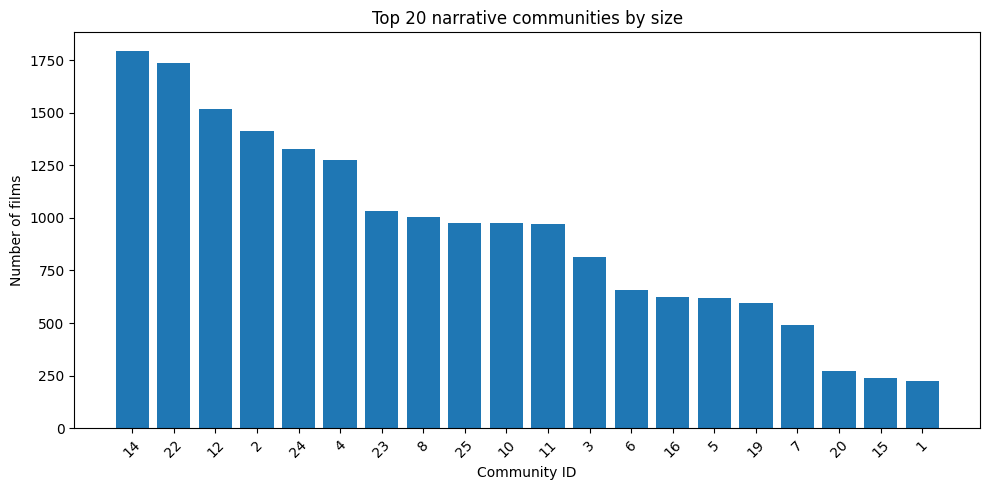

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/top_20_communities_by_size.png


In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(
    community_size_table.head(20)["community_id"].astype(str),
    community_size_table.head(20)["n_films"]
)
plt.title("Top 20 narrative communities by size")
plt.xlabel("Community ID")
plt.ylabel("Number of films")
plt.xticks(rotation=45)
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "top_20_communities_by_size.png"
plt.savefig(fig_path, dpi=200)
plt.show()

print("Saved:", fig_path)

## 7. Helper functions for thesis-ready tables

In [ ]:
# Helper functions for thesis-ready tables
# Stronger franchise/title-family normalization

import re

def make_title_family(title):
    """
    Creates a display-level title family.
    This is NOT used to change the graph.
    It is only used to avoid repetitive franchise rows in thesis tables.
    """

    raw = str(title).lower().strip()

    # Manual franchise roots for common repeated-title families
    franchise_patterns = {
        "scooby_doo": r"scooby[\s\-]*doo|\bscoob\b",
        "star_wars": r"star\s+wars",
        "harry_potter": r"harry\s+potter|fantastic\s+beasts",
        "lord_of_the_rings": r"lord\s+of\s+the\s+rings|hobbit",
        "batman": r"\bbatman\b|dark\s+knight",
        "superman": r"\bsuperman\b",
        "spider_man": r"spider[\s\-]*man",
        "x_men": r"\bx[\s\-]*men\b|wolverine",
        "avengers": r"\bavengers\b",
        "fast_furious": r"fast\s+.*furious|fast\s+five|fast\s+x",
        "mission_impossible": r"mission[\s:]*impossible",
        "james_bond": r"james\s+bond|007",
        "jurassic": r"jurassic\s+park|jurassic\s+world",
        "godzilla": r"\bgodzilla\b",
        "king_kong": r"king\s+kong",
        "pokemon": r"pok[eé]mon",
        "naruto": r"\bnaruto\b",
        "dragon_ball": r"dragon\s+ball",
        "one_piece": r"one\s+piece",
        "detective_conan": r"detective\s+conan|case\s+closed",
        "barbie": r"\bbarbie\b",
        "cinderella": r"\bcinderella\b",
        "snow_white": r"snow\s+white",
        "alice_wonderland": r"alice\s+.*wonderland",
        "christmas_carol": r"christmas\s+carol",
        "sherlock_holmes": r"sherlock\s+holmes",
        "zorro": r"\bzorro\b",
    }

    for family, pattern in franchise_patterns.items():
        if re.search(pattern, raw):
            return family

    # General normalization
    title = raw
    title = re.sub(r"['’]s\b", "", title)
    title = re.sub(r"[^a-z0-9\s]", " ", title)
    title = re.sub(r"\b(the|a|an)\b", " ", title)

    # Remove sequel/edition words
    title = re.sub(
        r"\b(part|chapter|episode|vol|volume|season|book|movie|film|return|revenge|rise|fall|curse|legend)\b\s*[ivx0-9]*",
        " ",
        title
    )

    # Remove roman numerals and years/numbers
    title = re.sub(r"\b[ivx]{1,5}\b", " ", title)
    title = re.sub(r"\b\d{1,4}\b", " ", title)

    # Clean spacing
    title = re.sub(r"\s+", " ", title).strip()

    # Fallback if empty
    if title == "":
        title = raw

    return title


def top_unique_by_family(df, metric, n=20):
    temp = df.copy()
    temp["title_family"] = temp["title"].apply(make_title_family)
    return (
        temp
        .sort_values(metric, ascending=False)
        .drop_duplicates("title_family")
        .head(n)
    )


def compact_cols(df):
    cols = [
        "title", "release_year", "primary_genre", "vote_count",
        "vote_average", "community_id",
        "degree", "weighted_degree",
        "pagerank", "betweenness_centrality_sampled",
        "eigenvector_centrality", "clustering_coefficient"
    ]
    return df[[c for c in cols if c in df.columns]].copy()


nodes["title_family"] = nodes["title"].apply(make_title_family)

print("Helpers ready.")
print("Unique title families:", nodes["title_family"].nunique())

Helpers ready.
Unique title families: 17566


##7b. Franchise concentration diagnostic


In [ ]:
# Franchise concentration diagnostic
# Shows which title families appear many times in the network

franchise_concentration = (
    nodes
    .groupby("title_family")
    .agg(
        n_titles=("title", "count"),
        example_titles=("title", lambda x: "; ".join(x.dropna().astype(str).head(8))),
        communities=("community_id", lambda x: "; ".join(map(str, sorted(x.dropna().unique())[:8]))),
        median_vote_count=("vote_count", "median"),
        max_weighted_degree=("weighted_degree", "max")
    )
    .reset_index()
    .sort_values(["n_titles", "max_weighted_degree"], ascending=[False, False])
)

display(franchise_concentration.head(30))

franchise_concentration.to_csv(
    OUTPUT_TABLES_DIR / "franchise_concentration_diagnostic.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "franchise_concentration_diagnostic.csv")

,title_family,n_titles,example_titles,communities,median_vote_count,max_weighted_degree
13670,scooby_doo,38,Scooby-Doo on Zombie Island; Scooby-Doo; Scooby-Doo and the Cyber Chase; Scooby-Doo 2: Monsters Unleashed; Scooby-Do...,19; 20; 21,213.0,14.478587
1369,barbie,27,The Shrimp on the Barbie; Barbie in the Nutcracker; Barbie as Rapunzel; Barbie as The Princess & the Pauper; Barbie:...,2; 3; 10; 18; 19; 22; 24,545.0,9.822428
1401,batman,24,Batman Returns; Batman: Mask of the Phantasm; Batman Forever; Batman & Robin; Batman: Mystery of the Batwoman; Batma...,18; 20; 22,624.0,12.213011
4184,detective_conan,24,Detective Conan: The Time Bombed Skyscraper; Detective Conan: The Private Eyes' Requiem; Case Closed: The Fourteenth...,10; 11; 12; 14,151.5,11.137357
3052,cinderella,18,A Chinese Odyssey Part Two: Cinderella; Cinderella II: Dreams Come True; Cinderella; Three Wishes for Cinderella; A ...,2; 3; 10; 12; 14; 16; 19; 22,218.0,10.722961
12391,pokemon,17,Pokémon 3: The Movie; Pokémon 4Ever; Pokémon Heroes; Pokémon: Jirachi - Wish Maker; Pokémon: Lucario and the Mystery...,10; 11; 19; 22,290.0,7.403845
6308,godzilla,15,Godzilla vs. King Ghidorah; Godzilla vs. Mothra; Godzilla vs. Mechagodzilla II; Godzilla vs. Destoroyah; Godzilla; G...,11,294.0,10.553043
14602,spider_man,11,Spider-Man 2; Spider-Man 3; The Amazing Spider-Man; Spider-Man: No Way Home; Spider-Man: The Venom Saga; The Amazing...,20,16265.0,10.761400
10945,naruto,11,Naruto the Movie: Ninja Clash in the Land of Snow; Naruto the Movie: Legend of the Stone of Gelel; Naruto Shippuden ...,12,603.0,9.331289
11684,one_piece,11,One Piece: Dead End Adventure; One Piece: Curse of the Sacred Sword; One Piece: Baron Omatsuri and the Secret Island...,10; 22,242.0,8.365757


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/franchise_concentration_diagnostic.csv


## 8. Global centrality tables

These tables are for interpretation, not fame ranking.

- `weighted_degree`: central inside dense semantic neighborhoods.
- `betweenness_centrality_sampled`: bridge-like position between neighborhoods.
- `pagerank`: structurally influential nodes considering neighbor importance.
- `eigenvector_centrality`: nodes connected to other central nodes.


In [ ]:
top_weighted_degree_raw = compact_cols(
    nodes.sort_values("weighted_degree", ascending=False).head(50)
)

top_weighted_degree_capped = compact_cols(
    top_unique_by_family(nodes, "weighted_degree", n=50)
)

top_betweenness = compact_cols(
    top_unique_by_family(nodes, "betweenness_centrality_sampled", n=50)
)

top_pagerank = compact_cols(
    top_unique_by_family(nodes, "pagerank", n=50)
)

print("Top weighted degree — raw:")
display(top_weighted_degree_raw.head(20))

print("Top weighted degree — franchise-capped:")
display(top_weighted_degree_capped.head(20))

print("Top betweenness — franchise-capped:")
display(top_betweenness.head(20))

top_weighted_degree_raw.to_csv(OUTPUT_TABLES_DIR / "top_weighted_degree_raw.csv", index=False)
top_weighted_degree_capped.to_csv(OUTPUT_TABLES_DIR / "top_weighted_degree_franchise_capped.csv", index=False)
top_betweenness.to_csv(OUTPUT_TABLES_DIR / "top_betweenness_franchise_capped.csv", index=False)
top_pagerank.to_csv(OUTPUT_TABLES_DIR / "top_pagerank_franchise_capped.csv", index=False)

print("Saved global centrality tables.")

Top weighted degree — raw:


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient
14843,Scooby-Doo's Creepiest Capers,2000,Animation,37.0,9.400,21,20,14.478587,0.000074,0.000011,0.258545,0.473681
10443,Scooby-Doo! Curse of the Lake Monster,2010,Mystery,527.0,6.200,21,20,13.918640,0.000071,0.000002,0.247758,0.468253
3301,Scooby-Doo,2002,Mystery,4744.0,6.099,21,20,13.827167,0.000074,0.000126,0.233844,0.418411
18274,The House,2024,Drama,41.0,6.900,14,20,13.276865,0.000091,0.000307,0.000073,0.146226
6824,The Kindred,2021,Horror,125.0,6.400,14,20,13.124843,0.000090,0.000343,0.000053,0.082442
9388,Amer,2009,Thriller,169.0,6.200,22,20,13.117239,0.000094,0.000102,0.000038,0.290791
2453,Scooby-Doo on Zombie Island,1998,Animation,831.0,7.700,21,20,13.116930,0.000067,0.000002,0.239730,0.460429
14187,Scoob!,2020,Animation,1800.0,7.000,21,20,13.114113,0.000068,0.000095,0.231001,0.422530
11462,Crescent City,2024,Crime,73.0,6.000,25,20,13.036527,0.000090,0.000225,0.000105,0.164514
15417,Pistas para volver a casa,2015,Mystery,26.0,6.800,14,20,13.012957,0.000088,0.000146,0.000079,0.210446


Top weighted degree — franchise-capped:


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient
14843,Scooby-Doo's Creepiest Capers,2000,Animation,37.0,9.400,21,20,14.478587,0.000074,0.000011,0.258545,0.473681
18274,The House,2024,Drama,41.0,6.900,14,20,13.276865,0.000091,0.000307,0.000073,0.146226
6824,The Kindred,2021,Horror,125.0,6.400,14,20,13.124843,0.000090,0.000343,0.000053,0.082442
9388,Amer,2009,Thriller,169.0,6.200,22,20,13.117239,0.000094,0.000102,0.000038,0.290791
11462,Crescent City,2024,Crime,73.0,6.000,25,20,13.036527,0.000090,0.000225,0.000105,0.164514
15417,Pistas para volver a casa,2015,Mystery,26.0,6.800,14,20,13.012957,0.000088,0.000146,0.000079,0.210446
7870,Revanche,2008,Crime,249.0,7.165,7,20,12.965736,0.000090,0.000253,0.000053,0.208048
7487,Beyond the Law,2019,Action,102.0,5.200,14,20,12.964603,0.000090,0.000399,0.000061,0.119705
14578,The Boogeyman,2023,Horror,1062.0,6.400,14,20,12.942888,0.000085,0.000176,0.000066,0.124121
2663,Panic,2000,Crime,121.0,6.200,7,20,12.934219,0.000089,0.000198,0.000055,0.244769


Top betweenness — franchise-capped:


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient
1466,The Bandit,1996,Crime,355.0,7.300,22,18,9.672851,0.000093,0.002223,4.225585e-06,0.003452
5489,The TV Set,2007,Comedy,89.0,6.000,6,13,6.224862,0.000077,0.002018,1.740066e-06,0.104251
1131,Ace Ventura: When Nature Calls,1995,Crime,4524.0,6.300,10,14,6.649705,0.000078,0.001957,1.154171e-06,0.016134
12323,Tom and Jerry: Snowman's Land,2022,Animation,49.0,6.700,10,14,6.761525,0.000088,0.001885,4.532014e-05,0.038170
2897,Intacto,2001,Action,196.0,6.600,23,18,9.807808,0.000094,0.001868,7.044299e-06,0.021826
352,The Perfect Weapon,1991,Action,124.0,6.200,10,16,8.534136,0.000098,0.001788,3.567781e-06,0.018160
5668,"Mommy, I'm Scared",2006,Drama,34.0,6.800,12,16,7.967083,0.000088,0.001665,1.634241e-06,0.024527
16101,Justin Timberlake + The Tennessee Kids,2016,Music,49.0,7.400,5,14,5.529081,0.000107,0.001658,2.824542e-08,0.078943
13742,Nightcrawler,2014,Crime,11648.0,7.709,1,16,8.254610,0.000100,0.001616,1.528015e-06,0.034920
10348,Swerve,2012,Crime,47.0,5.300,23,16,8.513560,0.000084,0.001611,3.696410e-06,0.036534


Saved global centrality tables.


In [ ]:
# Thesis-visible centrality tables
# Applies visibility rule for thesis examples only
# Does NOT change the graph

DISPLAY_MIN_VOTE_COUNT = 50

nodes_visible = nodes[nodes["vote_count"].fillna(0) >= DISPLAY_MIN_VOTE_COUNT].copy()

top_weighted_degree_visible_capped = compact_cols(
    top_unique_by_family(nodes_visible, "weighted_degree", n=50)
)

top_betweenness_visible_capped = compact_cols(
    top_unique_by_family(nodes_visible, "betweenness_centrality_sampled", n=50)
)

top_pagerank_visible_capped = compact_cols(
    top_unique_by_family(nodes_visible, "pagerank", n=50)
)

print("Top weighted degree — visible + franchise-capped:")
display(top_weighted_degree_visible_capped.head(20))

print("Top betweenness — visible + franchise-capped:")
display(top_betweenness_visible_capped.head(20))

top_weighted_degree_visible_capped.to_csv(
    OUTPUT_TABLES_DIR / "top_weighted_degree_visible_franchise_capped.csv",
    index=False
)

top_betweenness_visible_capped.to_csv(
    OUTPUT_TABLES_DIR / "top_betweenness_visible_franchise_capped.csv",
    index=False
)

top_pagerank_visible_capped.to_csv(
    OUTPUT_TABLES_DIR / "top_pagerank_visible_franchise_capped.csv",
    index=False
)

print("Saved visible thesis centrality tables.")

Top weighted degree — visible + franchise-capped:


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient
10443,Scooby-Doo! Curse of the Lake Monster,2010,Mystery,527.0,6.200,21,20,13.918640,0.000071,0.000002,0.247758,0.468253
6824,The Kindred,2021,Horror,125.0,6.400,14,20,13.124843,0.000090,0.000343,0.000053,0.082442
9388,Amer,2009,Thriller,169.0,6.200,22,20,13.117239,0.000094,0.000102,0.000038,0.290791
11462,Crescent City,2024,Crime,73.0,6.000,25,20,13.036527,0.000090,0.000225,0.000105,0.164514
7870,Revanche,2008,Crime,249.0,7.165,7,20,12.965736,0.000090,0.000253,0.000053,0.208048
7487,Beyond the Law,2019,Action,102.0,5.200,14,20,12.964603,0.000090,0.000399,0.000061,0.119705
14578,The Boogeyman,2023,Horror,1062.0,6.400,14,20,12.942888,0.000085,0.000176,0.000066,0.124121
2663,Panic,2000,Crime,121.0,6.200,7,20,12.934219,0.000089,0.000198,0.000055,0.244769
17345,Haunt,2019,Horror,1353.0,6.700,8,20,12.886360,0.000094,0.000122,0.000069,0.151657
16336,The Bachelors,2017,Comedy,173.0,7.100,14,20,12.878046,0.000091,0.000209,0.000052,0.132123


Top betweenness — visible + franchise-capped:


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient
1466,The Bandit,1996,Crime,355.0,7.300,22,18,9.672851,0.000093,0.002223,4.225585e-06,0.003452
5489,The TV Set,2007,Comedy,89.0,6.000,6,13,6.224862,0.000077,0.002018,1.740066e-06,0.104251
1131,Ace Ventura: When Nature Calls,1995,Crime,4524.0,6.300,10,14,6.649705,0.000078,0.001957,1.154171e-06,0.016134
2897,Intacto,2001,Action,196.0,6.600,23,18,9.807808,0.000094,0.001868,7.044299e-06,0.021826
352,The Perfect Weapon,1991,Action,124.0,6.200,10,16,8.534136,0.000098,0.001788,3.567781e-06,0.018160
13742,Nightcrawler,2014,Crime,11648.0,7.709,1,16,8.254610,0.000100,0.001616,1.528015e-06,0.034920
16448,Darkland,2017,Thriller,139.0,6.200,22,15,7.945254,0.000083,0.001571,2.199830e-06,0.030736
14981,Jungle,2017,Adventure,2118.0,6.600,14,18,9.971398,0.000098,0.001569,7.518445e-06,0.036694
7885,Beethoven's Big Break,2008,Family,160.0,5.200,10,17,8.382484,0.000093,0.001551,2.986021e-05,0.057845
8682,Animal Kingdom,2010,Crime,900.0,6.800,2,17,8.935982,0.000091,0.001549,2.546773e-06,0.030925


Saved visible thesis centrality tables.


In [ ]:
# Thesis display: top visible central film per major community
# This gives one representative row per community.

DISPLAY_MIN_VOTE_COUNT = 50

nodes_visible = nodes[nodes["vote_count"].fillna(0) >= DISPLAY_MIN_VOTE_COUNT].copy()

top_visible_central_per_community = []

for cid, g in nodes_visible.groupby("community_id"):
    g = g.copy()
    g["title_family"] = g["title"].apply(make_title_family)

    top = (
        g.sort_values("weighted_degree", ascending=False)
         .drop_duplicates("title_family")
         .head(3)
    )

    for rank, row in enumerate(top.itertuples(index=False), start=1):
        top_visible_central_per_community.append({
            "community_id": cid,
            "rank_within_community": rank,
            "title": row.title,
            "release_year": row.release_year,
            "primary_genre": row.primary_genre,
            "vote_count": row.vote_count,
            "vote_average": row.vote_average,
            "weighted_degree": row.weighted_degree,
            "betweenness_centrality_sampled": row.betweenness_centrality_sampled,
            "pagerank": row.pagerank
        })

top_visible_central_per_community = pd.DataFrame(top_visible_central_per_community)

top_visible_central_per_community = top_visible_central_per_community.merge(
    community_size_table[["community_id", "n_films", "top_genre"]],
    on="community_id",
    how="left"
)

top_visible_central_per_community = top_visible_central_per_community.sort_values(
    ["n_films", "community_id", "rank_within_community"],
    ascending=[False, True, True]
)

display(top_visible_central_per_community.head(60))

top_visible_central_per_community.to_csv(
    OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv")

,community_id,rank_within_community,title,release_year,primary_genre,vote_count,vote_average,weighted_degree,betweenness_centrality_sampled,pagerank,n_films,top_genre
42,14,1,The Kindred,2021,Horror,125.0,6.400,13.124843,0.000343,0.000090,1792,Drama
43,14,2,Beyond the Law,2019,Action,102.0,5.200,12.964603,0.000399,0.000090,1792,Drama
44,14,3,The Boogeyman,2023,Horror,1062.0,6.400,12.942888,0.000176,0.000085,1792,Drama
65,22,1,Amer,2009,Thriller,169.0,6.200,13.117239,0.000102,0.000094,1735,Drama
66,22,2,Something New,2016,Comedy,223.0,5.679,12.563270,0.000286,0.000090,1735,Drama
67,22,3,Mayday,2021,Mystery,62.0,5.000,12.478473,0.000297,0.000088,1735,Drama
36,12,1,Demon Slayer: Kimetsu no Yaiba - Sibling's Bond,2019,Animation,244.0,7.900,12.368310,0.000250,0.000097,1517,Drama
37,12,2,Samurai Cop,1991,Action,204.0,4.600,11.794232,0.000152,0.000093,1517,Drama
38,12,3,Ring 2,1999,Horror,459.0,5.800,11.458239,0.000547,0.000094,1517,Drama
6,2,1,Amanda,2018,Drama,295.0,7.100,12.291271,0.000386,0.000096,1411,Drama


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv


## 9. Representative films per community

For each major community, this section produces highest weighted-degree films, highest betweenness films, and most visible films by vote count.


In [ ]:
MIN_COMMUNITY_SIZE_FOR_INTERPRETATION = 100
TOP_N_PER_COMMUNITY = 10

major_communities = (
    community_size_table
    .query("n_films >= @MIN_COMMUNITY_SIZE_FOR_INTERPRETATION")
    ["community_id"]
    .tolist()
)

print("Major communities:", len(major_communities))
print(major_communities[:20])

Major communities: 23
[14, 22, 12, 2, 24, 4, 23, 8, 25, 10, 11, 3, 6, 16, 5, 19, 7, 20, 15, 1]


In [ ]:
community_representatives = []

for cid in major_communities:
    g = nodes[nodes["community_id"] == cid].copy()

    top_structural = top_unique_by_family(g, "weighted_degree", n=TOP_N_PER_COMMUNITY)
    top_bridge = top_unique_by_family(g, "betweenness_centrality_sampled", n=TOP_N_PER_COMMUNITY)
    top_visible = top_unique_by_family(g, "vote_count", n=TOP_N_PER_COMMUNITY)

    for label, table in [
        ("central_weighted_degree", top_structural),
        ("bridging_betweenness", top_bridge),
        ("visible_examples", top_visible)
    ]:
        for rank, row in enumerate(table.itertuples(index=False), start=1):
            community_representatives.append({
                "community_id": cid,
                "selection_type": label,
                "rank": rank,
                "title": row.title,
                "release_year": row.release_year,
                "primary_genre": row.primary_genre,
                "vote_count": row.vote_count,
                "vote_average": row.vote_average,
                "weighted_degree": row.weighted_degree,
                "betweenness_centrality_sampled": row.betweenness_centrality_sampled,
                "pagerank": row.pagerank
            })

community_representatives = pd.DataFrame(community_representatives)

display(community_representatives.head(30))

community_representatives.to_csv(
    OUTPUT_TABLES_DIR / "community_representative_films_long.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "community_representative_films_long.csv")

,community_id,selection_type,rank,title,release_year,primary_genre,vote_count,vote_average,weighted_degree,betweenness_centrality_sampled,pagerank
0,14,central_weighted_degree,1,The House,2024,Drama,41.0,6.900,13.276865,0.000307,0.000091
1,14,central_weighted_degree,2,The Kindred,2021,Horror,125.0,6.400,13.124843,0.000343,0.000090
2,14,central_weighted_degree,3,Pistas para volver a casa,2015,Mystery,26.0,6.800,13.012957,0.000146,0.000088
3,14,central_weighted_degree,4,Beyond the Law,2019,Action,102.0,5.200,12.964603,0.000399,0.000090
4,14,central_weighted_degree,5,The Boogeyman,2023,Horror,1062.0,6.400,12.942888,0.000176,0.000085
5,14,central_weighted_degree,6,The Bachelors,2017,Comedy,173.0,7.100,12.878046,0.000209,0.000091
6,14,central_weighted_degree,7,The Harbinger,2022,Thriller,41.0,4.800,12.853186,0.000268,0.000088
7,14,central_weighted_degree,8,House at the End of the Street,2012,Horror,1885.0,5.800,12.852241,0.000243,0.000089
8,14,central_weighted_degree,9,This Is Where I Leave You,2014,Drama,1450.0,6.600,12.804663,0.000399,0.000090
9,14,central_weighted_degree,10,"One Stays, the Other Leaves",2005,Comedy,32.0,5.100,12.603439,0.000176,0.000090


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_representative_films_long.csv


## 10. Community label helper table

This table does not automatically decide final community names. It gives evidence for manual labeling.

Do not overclaim. Community labels should be descriptive, not absolute.


In [ ]:
# Stronger community label helper table
# This table gives evidence for manual community naming.

def top_values_as_string(series, n=5):
    vc = series.dropna().astype(str).value_counts().head(n)
    return "; ".join([f"{idx} ({cnt})" for idx, cnt in vc.items()])


def titles_as_string(df, metric, n=8):
    top = top_unique_by_family(df, metric, n=n)
    return "; ".join([
        f"{r.title} ({int(r.release_year)})"
        for r in top.itertuples(index=False)
        if pd.notna(r.release_year)
    ])


def visible_titles_as_string(df, n=8):
    top = top_unique_by_family(df, "vote_count", n=n)
    return "; ".join([
        f"{r.title} ({int(r.release_year)})"
        for r in top.itertuples(index=False)
        if pd.notna(r.release_year)
    ])


community_rows = []

for cid in sorted(nodes["community_id"].dropna().unique()):
    g = nodes[nodes["community_id"] == cid].copy()

    community_rows.append({
        "community_id": cid,
        "n_films": len(g),
        "share_of_network_pct": round(len(g) / len(nodes) * 100, 2),

        "top_primary_genres": top_values_as_string(g["primary_genre"], 6),
        "median_year": g["release_year"].median(),
        "year_range": f"{int(g['release_year'].min())}-{int(g['release_year'].max())}",

        "median_vote_count": round(g["vote_count"].median(), 1),
        "median_vote_average": round(g["vote_average"].median(), 2),
        "revenue_available_pct": round(g["revenue_clean"].notna().mean() * 100, 2),

        "central_titles_weighted_degree": titles_as_string(g, "weighted_degree", n=8),
        "bridging_titles_betweenness": titles_as_string(g, "betweenness_centrality_sampled", n=6),
        "visible_titles_vote_count": visible_titles_as_string(g, n=8),

        # These are intentionally blank for manual thesis interpretation
        "suggested_label_manual": "",
        "interpretation_note_manual": ""
    })

community_label_helper_v2 = (
    pd.DataFrame(community_rows)
    .sort_values("n_films", ascending=False)
    .reset_index(drop=True)
)

display(community_label_helper_v2.head(20))

community_label_helper_v2.to_csv(
    OUTPUT_TABLES_DIR / "community_label_helper_v2_manual.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "community_label_helper_v2_manual.csv")

,community_id,n_films,share_of_network_pct,top_primary_genres,median_year,year_range,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual
0,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),2014.0,1990-2024,82.0,6.10,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023);...,Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way...,,
1,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),2014.0,1990-2024,79.0,6.30,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Da...",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Pari...,Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pa...,,
2,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),2013.0,1990-2024,61.0,6.60,34.15,Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008...,"Mommy, I'm Scared (2006); Under Construction (2003); Man Push Cart (2006); Apartment 1303 (2007); Amaran (2024); Yok...",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); T...,,
3,2,1411,7.35,Drama (449); Comedy (414); Horror (157); Romance (80); Thriller (80); Action (65),2012.0,1990-2024,102.0,6.00,41.11,Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020...,Die In One Day (2017); Animal Kingdom (2010); Agent Cody Banks (2003); Hope Springs (2003); Rose (2012); The Attic E...,Titanic (1997); Inside Out (2015); Toy Story (1995); Get Out (2017); Once Upon a Time... in Hollywood (2019); The Cu...,,
4,24,1327,6.91,Drama (503); Comedy (409); Horror (67); Thriller (63); Romance (61); Crime (49),2014.0,1990-2024,99.0,6.10,34.97,What's in a Name (2012); A Family (2017); The Royal Siren (2010); Simon's Got a Gift (2020); A Taste of Ink (2017); ...,The Sweet Life (2017); Stormskerry Maja (2024); Soul Mates (2023); Adaptation. (2002); The Minister (2011); By the G...,Up (2009); Kill Bill: Vol. 2 (2004); Divergent (2014); Me Before You (2016); Prisoners (2013); Amélie (2001); Soul (...,,
5,4,1276,6.65,Drama (431); Action (222); Comedy (195); War (113); Horror (59); Thriller (46),2013.0,1990-2024,86.5,6.28,40.44,Sobibor (2018); Europa Europa (1990); Allies (2014); Legatee (2012); Russendisko (2012); No Way Up (2024); Panfilov'...,Mandragora (1997); Russendisko (2012); The Believer (2001); Jojo Rabbit (2019); Welcome to Sarajevo (1997); All Supe...,Inglourious Basterds (2009); Dunkirk (2017); Saving Private Ryan (1998); The Grand Budapest Hotel (2014); V for Vend...,,
6,23,1031,5.37,Action (232); Comedy (207); Drama (203); Crime (119); Thriller (92); Horror (50),2011.0,1990-2024,123.0,6.10,45.68,Living & Dying (2007); 7 Minutes (2014); Rabid Dogs (2015); Run & Gun (2022); Thunivu (2023); Poker Face (2022); Blo...,Intacto (2001); Swerve (2012); Sollers Point (2017); Cat and Dog (2024); Enemies Closer (2013); Poker Face (2022),Fight Club (1999); The Shawshank Redemption (1994); Catch Me If You Can (2002); The Departed (2006); Reservoir Dogs ...,,
7,8,1005,5.23,Horror (284); Comedy (255); Drama (166); Thriller (80); Action (45); Crime (31),2013.0,1990-2024,100.0,5.80,36.42,Haunt (2019); Death's Roulette (2023); Talon Falls (2017); Tales of Halloween (2015); Animal (2014); Melancholie der...,Tempus Tormentum (2018); Last Girl Sta

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_label_helper_v2_manual.csv


## 10b. Manual community interpretation template

In [ ]:
# Manual community interpretation template
# Edit suggested_label_manual and interpretation_note_manual after inspecting outputs.

community_manual_template = community_label_helper_v2.copy()

# Keep only major communities for manual thesis interpretation first
community_manual_template = community_manual_template[
    community_manual_template["n_films"] >= 100
].copy()

# Add a priority rank
community_manual_template["interpretation_priority"] = range(1, len(community_manual_template) + 1)

# Reorder columns
community_manual_template = community_manual_template[
    [
        "interpretation_priority",
        "community_id",
        "n_films",
        "share_of_network_pct",
        "top_primary_genres",
        "year_range",
        "median_year",
        "median_vote_count",
        "median_vote_average",
        "revenue_available_pct",
        "central_titles_weighted_degree",
        "bridging_titles_betweenness",
        "visible_titles_vote_count",
        "suggested_label_manual",
        "interpretation_note_manual"
    ]
].copy()

display(community_manual_template.head(20))

community_manual_template.to_csv(
    OUTPUT_TABLES_DIR / "community_manual_labeling_template.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "community_manual_labeling_template.csv")

,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,year_range,median_year,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual
0,1,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),1990-2024,2014.0,82.0,6.10,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023);...,Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way...,,
1,2,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),1990-2024,2014.0,79.0,6.30,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Da...",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Pari...,Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pa...,,
2,3,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),1990-2024,2013.0,61.0,6.60,34.15,Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008...,"Mommy, I'm Scared (2006); Under Construction (2003); Man Push Cart (2006); Apartment 1303 (2007); Amaran (2024); Yok...",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); T...,,
3,4,2,1411,7.35,Drama (449); Comedy (414); Horror (157); Romance (80); Thriller (80); Action (65),1990-2024,2012.0,102.0,6.00,41.11,Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020...,Die In One Day (2017); Animal Kingdom (2010); Agent Cody Banks (2003); Hope Springs (2003); Rose (2012); The Attic E...,Titanic (1997); Inside Out (2015); Toy Story (1995); Get Out (2017); Once Upon a Time... in Hollywood (2019); The Cu...,,
4,5,24,1327,6.91,Drama (503); Comedy (409); Horror (67); Thriller (63); Romance (61); Crime (49),1990-2024,2014.0,99.0,6.10,34.97,What's in a Name (2012); A Family (2017); The Royal Siren (2010); Simon's Got a Gift (2020); A Taste of Ink (2017); ...,The Sweet Life (2017); Stormskerry Maja (2024); Soul Mates (2023); Adaptation. (2002); The Minister (2011); By the G...,Up (2009); Kill Bill: Vol. 2 (2004); Divergent (2014); Me Before You (2016); Prisoners (2013); Amélie (2001); Soul (...,,
5,6,4,1276,6.65,Drama (431); Action (222); Comedy (195); War (113); Horror (59); Thriller (46),1990-2024,2013.0,86.5,6.28,40.44,Sobibor (2018); Europa Europa (1990); Allies (2014); Legatee (2012); Russendisko (2012); No Way Up (2024); Panfilov'...,Mandragora (1997); Russendisko (2012); The Believer (2001); Jojo Rabbit (2019); Welcome to Sarajevo (1997); All Supe...,Inglourious Basterds (2009); Dunkirk (2017); Saving Private Ryan (1998); The Grand Budapest Hotel (2014); V for Vend...,,
6,7,23,1031,5.37,Action (232); Comedy (207); Drama (203); Crime (119); Thriller (92); Horror (50),1990-2024,2011.0,123.0,6.10,45.68,Living & Dying (2007); 7 Minutes (2014); Rabid Dogs (2015); Run & Gun (2022); Thunivu (2023); Poker Face (2022); Blo...,Intacto (2001); Swerve (2012); Sollers Point (2017); Cat and Dog (2024); Enemies Closer (2013); Poker Face (2022),Fight Club (1999); The Shawshank Redemption (1994); Catch Me If You Can (2002); The Departed (2006); Reservoir Dogs ...,,
7,8,8,1005,5.23,Horror (284); Comedy (255); Drama (166); Thriller (80); Action (45); Crime (31),1990-2024,2013.0,100.0,5.80,36.42,Haunt (2019); Death's Roulette (2023); Talon Falls (2017); Tales of Halloween (2015); Animal (2014); Melancholie der..

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template.csv


## 10c. Thesis-ready major community table

In [ ]:
# Thesis-ready major community table
# Compact version for thesis/report

major_community_thesis_table = community_label_helper_v2[
    community_label_helper_v2["n_films"] >= 100
].copy()

major_community_thesis_table = major_community_thesis_table[
    [
        "community_id",
        "n_films",
        "share_of_network_pct",
        "top_primary_genres",
        "central_titles_weighted_degree",
        "visible_titles_vote_count",
        "suggested_label_manual"
    ]
].copy()

display(major_community_thesis_table.head(20))

major_community_thesis_table.to_csv(
    OUTPUT_TABLES_DIR / "major_community_thesis_table.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "major_community_thesis_table.csv")

,community_id,n_films,share_of_network_pct,top_primary_genres,central_titles_weighted_degree,visible_titles_vote_count,suggested_label_manual
0,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023);...,Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way...,
1,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Da...",Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pa...,
2,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008...,Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); T...,
3,2,1411,7.35,Drama (449); Comedy (414); Horror (157); Romance (80); Thriller (80); Action (65),Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020...,Titanic (1997); Inside Out (2015); Toy Story (1995); Get Out (2017); Once Upon a Time... in Hollywood (2019); The Cu...,
4,24,1327,6.91,Drama (503); Comedy (409); Horror (67); Thriller (63); Romance (61); Crime (49),What's in a Name (2012); A Family (2017); The Royal Siren (2010); Simon's Got a Gift (2020); A Taste of Ink (2017); ...,Up (2009); Kill Bill: Vol. 2 (2004); Divergent (2014); Me Before You (2016); Prisoners (2013); Amélie (2001); Soul (...,
5,4,1276,6.65,Drama (431); Action (222); Comedy (195); War (113); Horror (59); Thriller (46),Sobibor (2018); Europa Europa (1990); Allies (2014); Legatee (2012); Russendisko (2012); No Way Up (2024); Panfilov'...,Inglourious Basterds (2009); Dunkirk (2017); Saving Private Ryan (1998); The Grand Budapest Hotel (2014); V for Vend...,
6,23,1031,5.37,Action (232); Comedy (207); Drama (203); Crime (119); Thriller (92); Horror (50),Living & Dying (2007); 7 Minutes (2014); Rabid Dogs (2015); Run & Gun (2022); Thunivu (2023); Poker Face (2022); Blo...,Fight Club (1999); The Shawshank Redemption (1994); Catch Me If You Can (2002); The Departed (2006); Reservoir Dogs ...,
7,8,1005,5.23,Horror (284); Comedy (255); Drama (166); Thriller (80); Action (45); Crime (31),Haunt (2019); Death's Roulette (2023); Talon Falls (2017); Tales of Halloween (2015); Animal (2014); Melancholie der...,The Maze Runner (2014); The Hangover (2009); Despicable Me (2010); Jumanji: Welcome to the Jungle (2017); Jumanji: T...,
8,25,977,5.09,Horror (217); Drama (200); Thriller (123); Comedy (112); Action (104); Crime (95),Crescent City (2024); The Deal (2015); Legendary Assassin (2008); Slice (2009); Asylum of Fear (2018); The Chronicle...,Se7en (1995); Eternal Sunshine of the Spotless Mind (2004); Memento (2000); The Conjuring (2013); Taken (2008); 12 Y...,
9,10,974,5.07,Animation (161); Comedy (159); Horror (120); Drama (108); Adventure (105); Action (104),Shark Attack 3: Megalodon (2002); All Is Lost (2013); Raiders of the Lost Shark (2015); Shark Waters (2022); Shark B...,Black Panther (2018); Pirates of the Caribbean: The Curse of the Black Pearl (2003); The Lion King (1994); Shrek (20...,


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/major_community_thesis_table.csv


## 11. Bridging films

High betweenness films can be interpreted as films that sit between semantic neighborhoods.

Because betweenness was sampled in Notebook 3, use it as an approximate structural signal, not an exact universal ranking.


In [ ]:
bridging_films = compact_cols(
    top_unique_by_family(nodes, "betweenness_centrality_sampled", n=100)
)

display(bridging_films.head(30))

bridging_films.to_csv(OUTPUT_TABLES_DIR / "bridging_films_betweenness.csv", index=False)

print("Saved:", OUTPUT_TABLES_DIR / "bridging_films_betweenness.csv")

,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient
1466,The Bandit,1996,Crime,355.0,7.300,22,18,9.672851,0.000093,0.002223,4.225585e-06,0.003452
5489,The TV Set,2007,Comedy,89.0,6.000,6,13,6.224862,0.000077,0.002018,1.740066e-06,0.104251
1131,Ace Ventura: When Nature Calls,1995,Crime,4524.0,6.300,10,14,6.649705,0.000078,0.001957,1.154171e-06,0.016134
12323,Tom and Jerry: Snowman's Land,2022,Animation,49.0,6.700,10,14,6.761525,0.000088,0.001885,4.532014e-05,0.038170
2897,Intacto,2001,Action,196.0,6.600,23,18,9.807808,0.000094,0.001868,7.044299e-06,0.021826
352,The Perfect Weapon,1991,Action,124.0,6.200,10,16,8.534136,0.000098,0.001788,3.567781e-06,0.018160
5668,"Mommy, I'm Scared",2006,Drama,34.0,6.800,12,16,7.967083,0.000088,0.001665,1.634241e-06,0.024527
16101,Justin Timberlake + The Tennessee Kids,2016,Music,49.0,7.400,5,14,5.529081,0.000107,0.001658,2.824542e-08,0.078943
13742,Nightcrawler,2014,Crime,11648.0,7.709,1,16,8.254610,0.000100,0.001616,1.528015e-06,0.034920
10348,Swerve,2012,Crime,47.0,5.300,23,16,8.513560,0.000084,0.001611,3.696410e-06,0.036534


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/bridging_films_betweenness.csv


## 12. Peripheral / unusual films

Peripheral films are low-degree and low-clustering films in the largest component.

Interpret carefully: peripheral does not mean bad or unsuccessful. It means semantically less embedded in the local similarity network.


In [ ]:
peripheral_candidates = nodes.copy()

peripheral_candidates = peripheral_candidates[peripheral_candidates["vote_count"].fillna(0) >= 50].copy()

peripheral_films = (
    peripheral_candidates
    .sort_values(["degree", "weighted_degree", "clustering_coefficient"], ascending=[True, True, True])
    [["title", "release_year", "primary_genre", "vote_count", "vote_average", "community_id",
      "degree", "weighted_degree", "clustering_coefficient"]]
    .head(100)
)

display(peripheral_films.head(30))

peripheral_films.to_csv(OUTPUT_TABLES_DIR / "peripheral_films_candidates.csv", index=False)

print("Saved:", OUTPUT_TABLES_DIR / "peripheral_films_candidates.csv")

,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,clustering_coefficient
9682,Fatal,2010,Comedy,663.0,6.000,5,1,0.337294,0.0
6361,Once,2007,Drama,1440.0,7.415,5,1,0.350222,0.0
7413,24 City,2008,Drama,60.0,7.000,25,1,0.350621,0.0
5941,Joe Strummer: The Future Is Unwritten,2007,Music,84.0,7.220,5,1,0.351685,0.0
17641,Gaston Lagaffe,2018,Comedy,248.0,4.900,10,1,0.357399,0.0
9426,The Conference,2022,History,127.0,6.700,4,1,0.367849,0.0
13983,Blue Exorcist: The Movie,2012,Animation,172.0,7.300,5,1,0.371739,0.0
15693,Check Point,2017,Action,63.0,6.100,4,1,0.373659,0.0
18847,Skyfire,2019,Action,304.0,6.363,12,1,0.373755,0.0
17620,Green Book,2018,Drama,12801.0,8.223,2,1,0.374469,0.0


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/peripheral_films_candidates.csv


## 13. Community-level outcome summary

This is not the final success model. It is an exploratory descriptive table showing whether some communities have stronger revenue/rating visibility.

Formal success/star-power modeling happens later.


In [ ]:
community_outcome_summary = (
    nodes
    .groupby("community_id")
    .agg(
        n_films=("node_id", "count"),
        revenue_available_pct=("revenue_clean", lambda x: round(x.notna().mean() * 100, 2)),
        median_revenue=("revenue_clean", "median"),
        mean_log_revenue=("log_revenue", "mean"),
        median_vote_average=("vote_average", "median"),
        median_vote_count=("vote_count", "median"),
        median_popularity=("popularity", "median"),
        median_weighted_degree=("weighted_degree", "median"),
        median_betweenness=("betweenness_centrality_sampled", "median")
    )
    .reset_index()
    .sort_values("n_films", ascending=False)
)

display(community_outcome_summary.head(20))

community_outcome_summary.to_csv(OUTPUT_TABLES_DIR / "community_outcome_summary_descriptive.csv", index=False)

print("Saved:", OUTPUT_TABLES_DIR / "community_outcome_summary_descriptive.csv")

,community_id,n_films,revenue_available_pct,median_revenue,mean_log_revenue,median_vote_average,median_vote_count,median_popularity,median_weighted_degree,median_betweenness
14,14,1792,36.38,4216409.0,14.965711,6.1000,82.0,1.52975,4.870969,0.000172
22,22,1735,32.16,3014802.0,14.680169,6.3000,79.0,1.27090,4.393519,0.000175
12,12,1517,34.15,7352642.0,15.421435,6.6000,61.0,1.68390,4.047611,0.000161
2,2,1411,41.11,7680455.5,15.268380,6.0000,102.0,1.57790,4.501107,0.000162
24,24,1327,34.97,4881639.5,14.991412,6.1000,99.0,1.39780,4.285003,0.000163
4,4,1276,40.44,5218006.5,15.224878,6.2790,86.5,1.47260,4.194384,0.000168
23,23,1031,45.68,11782282.0,15.786135,6.1000,123.0,1.87860,4.058141,0.000159
8,8,1005,36.42,9120108.5,15.436033,5.8000,100.0,1.56170,4.957902,0.000166
25,25,977,33.57,6024477.0,15.239825,6.0000,87.0,1.51200,4.472257,0.000167
10,10,974,48.05,20136563.0,16.458710,6.1000,128.5,1.89800,4.022564,0.000164


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_outcome_summary_descriptive.csv


## 14. Thesis-ready interpretation notes

In [ ]:
notes = f"""
Network interpretation notes

The semantic network contains {len(nodes):,} films in its largest connected component and {len(edges):,} mutual-KNN similarity edges.
The graph is interpreted as a plot-similarity network: edges represent semantic proximity between film overviews, not financial success, fame, or quality.

Community detection identifies {nodes["community_id"].nunique()} narrative communities. These communities should be interpreted as recurring semantic neighborhoods of plot description rather than strict genre categories.

Centrality is interpreted structurally:
- weighted degree identifies films located in dense local neighborhoods of similar plots;
- PageRank and eigenvector centrality identify films connected to other structurally important films;
- sampled betweenness identifies films that may bridge different narrative neighborhoods.

Because franchise films can form dense local clusters, the thesis reports both raw centrality tables and franchise-capped display tables. The graph itself is not altered by this display rule; the rule is used only to avoid repetitive examples in thesis tables.

Commercial-success interpretation remains descriptive at this stage. Revenue coverage is incomplete and formal success modeling is handled in a later notebook.
""".strip()

notes_path = OUTPUT_TABLES_DIR / "network_interpretation_notes.txt"
notes_path.write_text(notes, encoding="utf-8")

print(notes)
print("\nSaved:", notes_path)

Network interpretation notes

The semantic network contains 19,202 films in its largest connected component and 86,685 mutual-KNN similarity edges.
The graph is interpreted as a plot-similarity network: edges represent semantic proximity between film overviews, not financial success, fame, or quality.

Community detection identifies 26 narrative communities. These communities should be interpreted as recurring semantic neighborhoods of plot description rather than strict genre categories.

Centrality is interpreted structurally:
- weighted degree identifies films located in dense local neighborhoods of similar plots;
- PageRank and eigenvector centrality identify films connected to other structurally important films;
- sampled betweenness identifies films that may bridge different narrative neighborhoods.

Because franchise films can form dense local clusters, the thesis reports both raw centrality tables and franchise-capped display tables. The graph itself is not altered by this disp

## 15. Final output list

In [ ]:
outputs = [
    OUTPUT_TABLES_DIR / "network_interpretation_basic_checks.csv",
    OUTPUT_TABLES_DIR / "remaining_event_like_titles_check.csv",
    OUTPUT_TABLES_DIR / "community_size_overview.csv",
    OUTPUT_TABLES_DIR / "top_weighted_degree_raw.csv",
    OUTPUT_TABLES_DIR / "top_weighted_degree_franchise_capped.csv",
    OUTPUT_TABLES_DIR / "top_betweenness_franchise_capped.csv",
    OUTPUT_TABLES_DIR / "top_pagerank_franchise_capped.csv",
    OUTPUT_TABLES_DIR / "community_representative_films_long.csv",
    OUTPUT_TABLES_DIR / "community_label_helper.csv",
    OUTPUT_TABLES_DIR / "bridging_films_betweenness.csv",
    OUTPUT_TABLES_DIR / "peripheral_films_candidates.csv",
    OUTPUT_TABLES_DIR / "community_outcome_summary_descriptive.csv",
    OUTPUT_TABLES_DIR / "network_interpretation_notes.txt",
    OUTPUT_FIGURES_DIR / "top_20_communities_by_size.png",
    OUTPUT_TABLES_DIR / "franchise_concentration_diagnostic.csv",
    OUTPUT_TABLES_DIR / "community_label_helper_v2_manual.csv",
    OUTPUT_TABLES_DIR / "community_manual_labeling_template.csv",
    OUTPUT_TABLES_DIR / "major_community_thesis_table.csv"
]

print("Created/expected outputs:")
for p in outputs:
    print(p.exists(), "-", p)

Created/expected outputs:
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_interpretation_basic_checks.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/remaining_event_like_titles_check.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_size_overview.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_weighted_degree_raw.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_weighted_degree_franchise_capped.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_betweenness_franchise_capped.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_pagerank_franchise_capped.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_representative_films_long.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_label_helper.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/b

In [ ]:
from pathlib import Path
import pandas as pd

# ============================================================
# Paths
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

src = OUTPUT_TABLES_DIR / "community_manual_labeling_template.csv"
updates_path = OUTPUT_TABLES_DIR / "community_labels_snippet.csv"
dst = OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv"

print("Reading base file from:", src)
print("Reading labels file from:", updates_path)
print("Saving labeled file to:", dst)

# Check files exist before reading
if not src.exists():
    raise FileNotFoundError(f"Base file not found: {src}")

if not updates_path.exists():
    raise FileNotFoundError(f"Labels snippet file not found: {updates_path}")

# ============================================================
# Load files
# ============================================================

base = pd.read_csv(src)
updates = pd.read_csv(updates_path)

print("Base shape:", base.shape)
print("Updates shape:", updates.shape)

# ============================================================
# Merge labels into base template
# ============================================================

out = (
    base
    .drop(columns=["suggested_label_manual", "interpretation_note_manual"], errors="ignore")
    .merge(
        updates,
        on=["interpretation_priority", "community_id", "n_films"],
        how="left",
        validate="one_to_one"
    )
)

# ============================================================
# Validation
# ============================================================

missing = out["suggested_label_manual"].isna() | out["interpretation_note_manual"].isna()

if missing.any():
    missing_ids = out.loc[missing, "community_id"].tolist()
    raise ValueError(f"Missing labels/notes for communities: {missing_ids}")

if len(out) != len(base):
    raise ValueError(f"Row count changed: base={len(base)}, out={len(out)}")

# ============================================================
# Save labeled file
# ============================================================

out.to_csv(dst, index=False, encoding="utf-8")

print(f"\nSaved successfully: {dst}")
print("\nPreview:")
print(
    out[
        [
            "interpretation_priority",
            "community_id",
            "n_films",
            "suggested_label_manual"
        ]
    ].to_string(index=False)
)

Reading base file from: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template.csv
Reading labels file from: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_labels_snippet.csv
Saving labeled file to: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
Base shape: (23, 15)
Updates shape: (23, 5)

Saved successfully: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv

Preview:
 interpretation_priority  community_id  n_films                                                  suggested_label_manual
                       1            14     1792            Broad personal drama, family disruption, and domestic threat
                       2            22     1735     Relationship drama, romantic comedy, and emotional-family crossover
                       3            12     1517      Japanese/Korean action-animation and cro

## 16. What comes next

After this notebook, the next step is:

`05_success_and_star_power.ipynb`

Core model logic:

```text
plot structure / community / network position
+ star power
+ year controls
+ genre controls
→ success outcome
```
